# 과대적합과 과소적합 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week02/overfitting/lab/overfitting.ipynb)

측정 데이터에서 오차 0 인 모델이 새 데이터에서는 왜 틀릴까? 슬라이드의 성적표를 직접 재현하고, 교차 검증으로 모델을 골라 본다.

- **파트 1**: 직선 · 2차 · 9차 곡선을 맞추고 평균 절대 오차(MAE) 재기
- **파트 2**: 5겹 교차 검증 직접 구현
- **파트 3**: 1920년대에 실제로 잰 자동차 50대의 속도와 제동거리: 교차 검증으로 차수 고르기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

## 슬라이드의 예시 데이터

속도(km/h) 와 제동거리(m). 측정 데이터 10개와, 모델을 다 만든 뒤에 새로 잰 데이터 6개.

In [ ]:
# Same example as the slides: braking distance = physics law + measurement noise
speed = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)      # km/h
dist = np.array([2, 7, 0, 14, 14, 18, 25, 33, 45, 59], dtype=float)           # m
speed_new = np.array([15, 35, 45, 65, 85, 95], dtype=float)                   # new measurements
dist_new = np.array([3, 9, 6, 19, 45, 54], dtype=float)
plt.scatter(speed, dist, label="measured"); plt.scatter(speed_new, dist_new, marker="^", label="new")
plt.xlabel("speed (km/h)"); plt.ylabel("braking distance (m)"); plt.legend(); plt.show()

**예상 결과**

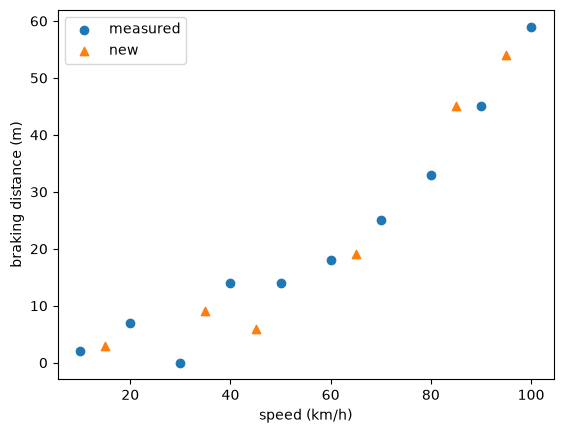

## 파트 1. 세 모델의 성적표

$d$차 다항식 $h(x) = w_0 + w_1 x + \cdots + w_d x^d$ 를 최소제곱으로 맞춘다. 속도를 $(x - 55)/27$ 로 줄여서 계산하면 9차에서도 숫자가 안정적이다 (곡선은 같다).

$$\text{MAE} = \frac{1}{m}\sum_{i=1}^{m} \big|\,h(x^{(i)}) - y^{(i)}\,\big|$$

In [ ]:
def fit_poly(x, y, degree):
    V = np.vander((x - 55) / 27, degree + 1)
    w, *_ = np.linalg.lstsq(V, y, rcond=None)
    return lambda t: np.vander((np.asarray(t, float) - 55) / 27, degree + 1) @ w

def mae(model, x, y):
    return None  # TODO: mean absolute error

line = fit_poly(speed, dist, 1)
print(f"line at 10 km/h: {line([10.0])[0]:.1f} m   MAE = {mae(line, speed, dist):.1f} m")

**예상 결과**

```
line at 10 km/h: -5.1 m   MAE = 5.5 m
```

In [ ]:
degrees = {"line": 1, "quadratic": 2, "wiggly (9th)": 9}
ts = np.linspace(5, 105, 300)
plt.scatter(speed, dist, color="k", zorder=3); plt.scatter(speed_new, dist_new, marker="^", color="r", zorder=3)
for name, d in degrees.items():
    model = fit_poly(speed, dist, d)
    err_new = None  # TODO: MAE on the new data
    print(f"{name:13s}: measured {mae(model, speed, dist):4.1f} m   new {err_new:4.1f} m")
    plt.plot(ts, model(ts), label=name)
plt.ylim(-15, 75); plt.xlabel("speed (km/h)"); plt.ylabel("braking distance (m)"); plt.legend(); plt.show()

**예상 결과**

```
line         : measured  5.5 m   new  6.4 m
quadratic    : measured  2.3 m   new  3.1 m
wiggly (9th) : measured  0.0 m   new  9.1 m
```

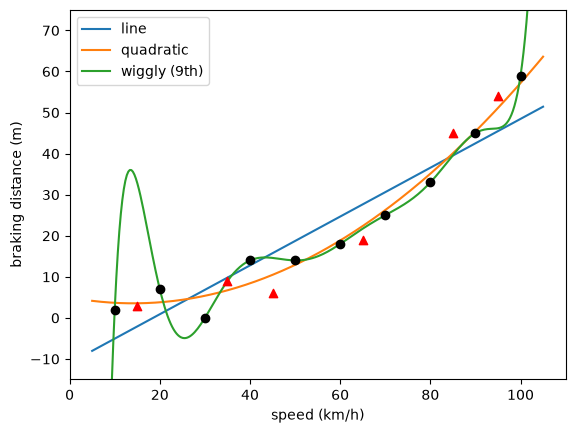

**확인**: 슬라이드 성적표는 측정 5 / 2 / 0 m, 새 데이터 6 / 3 / 9 m. 9차 곡선이 15 km/h 에서 얼마를 예측하는지도 찍어 보자.

## 파트 2. 5겹 교차 검증 직접 구현

새 데이터는 미리 없다고 치고, 측정 데이터 10개만으로 고른다. 조각 $k$ = $k$번째 점과 $k+5$번째 점 (`np.arange(10)[k::5]`). 한 조각을 숨기고 나머지 8개로 학습, 숨긴 2개의 MAE. 다섯 번의 평균이 교차 검증 오차.

In [ ]:
def cross_val_mae(x, y, degree, k=5):
    idx = np.arange(len(x))
    errors = []
    for i in range(k):
        val = idx[i::k]                                   # hidden points
        train = None  # TODO: all the other points
        model = fit_poly(x[train], y[train], degree)
        errors.append(None)  # TODO: MAE on the hidden points
    return np.mean(errors)

for name, d in degrees.items():
    print(f"{name:13s}: CV MAE {cross_val_mae(speed, dist, d):6.1f} m")

**예상 결과**

```
line         : CV MAE    6.8 m
quadratic    : CV MAE    3.3 m
wiggly (9th) : CV MAE  121.5 m
```

In [ ]:
# All degrees from 1 to 9: measured error vs cross-validation error
ds = range(1, 10)
train_err = [mae(fit_poly(speed, dist, d), speed, dist) for d in ds]
cv_err = [cross_val_mae(speed, dist, d) for d in ds]
plt.plot(ds, np.maximum(train_err, 0.05), "o-", label="measured (train)")
plt.plot(ds, cv_err, "s-", label="5-fold CV")
plt.yscale("log"); plt.xlabel("degree"); plt.ylabel("MAE (m)"); plt.legend(); plt.show()
print("best degree by CV:", list(ds)[int(np.argmin(cv_err))])

**예상 결과**

```
best degree by CV: 3
```

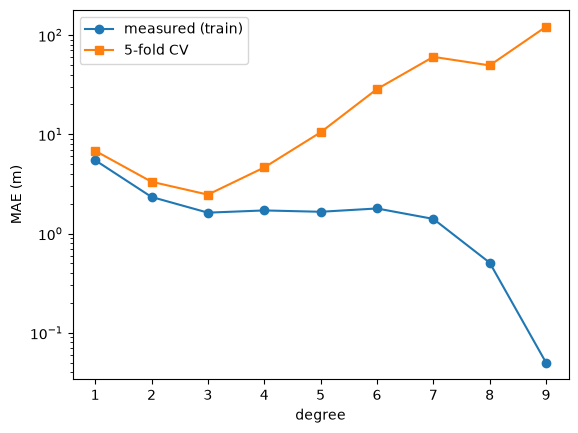

**관찰**: 측정 오차는 계속 줄지만 교차 검증 오차는 U자. 3차와 2차가 거의 같다면 어느 쪽을 고르겠는가?

## 파트 3. 실제 자동차 50대: 속도 → 제동거리

`cars`: 1920년대에 잰 자동차 50대 (속도 mph, 제동거리 ft). 처음 실행하면 CSV 를 내려받는다. 이번에는 scikit-learn 의 `cross_val_score` 로 5겹 교차 검증을 한다 (`shuffle=True`: 섞어서 조각을 나눈다).

In [ ]:
import pandas as pd
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

url = "https://vincentarelbundock.github.io/Rdatasets/csv/datasets/cars.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/cars.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/cars.csv")
df = pd.read_csv("data/cars.csv")
print(len(df), "cars"); print(df[["speed", "dist"]].head())
plt.scatter(df["speed"], df["dist"]); plt.xlabel("speed (mph)"); plt.ylabel("braking distance (ft)"); plt.show()

**예상 결과**

```
50 cars
   speed  dist
0      4     2
1      4    10
2      7     4
3      7    22
4      8    16
```

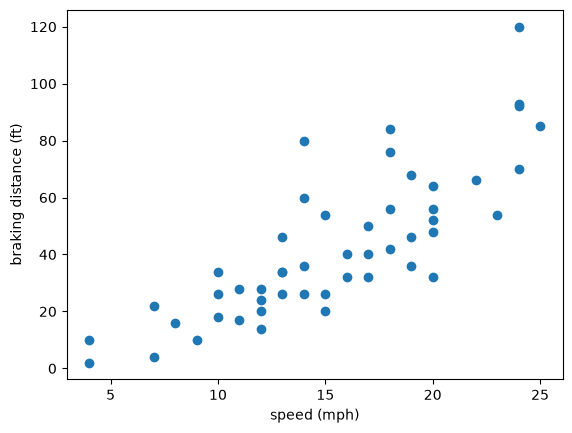

In [ ]:
def cv_mae_sklearn(X, y, degree):
    model = make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression())
    folds = KFold(5, shuffle=True, random_state=0)
    scores = cross_val_score(model, X, y, cv=folds, scoring="neg_mean_absolute_error")
    return None  # TODO: mean CV MAE (scores are negative)

X, y = df[["speed"]].to_numpy(float), df["dist"].to_numpy(float)
for d in range(1, 9):
    model = make_pipeline(StandardScaler(), PolynomialFeatures(d), LinearRegression()).fit(X, y)
    train = np.mean(np.abs(model.predict(X) - y))
    print(f"degree {d}: train MAE {train:5.2f} ft   CV MAE {cv_mae_sklearn(X, y, d):5.2f} ft")

**예상 결과**

```
degree 1: train MAE 11.58 ft   CV MAE 11.80 ft
degree 2: train MAE 11.11 ft   CV MAE 11.41 ft
degree 3: train MAE 11.03 ft   CV MAE 11.85 ft
degree 4: train MAE 10.95 ft   CV MAE 11.94 ft
degree 5: train MAE 10.96 ft   CV MAE 12.78 ft
degree 6: train MAE 10.82 ft   CV MAE 12.97 ft
degree 7: train MAE 10.70 ft   CV MAE 12.97 ft
degree 8: train MAE 10.59 ft   CV MAE 15.07 ft
```

**확인 질문**
1. 파트 1 에서 측정 오차로만 고르면 몇 차를 고르게 되나? 새 데이터에서는?
2. 파트 2 의 교차 검증이 9차에서 121 m 처럼 크게 나오는 이유를 그림으로 설명해 보자 (8개로 학습한 9차 곡선을 그려 보면 된다).
3. 파트 3 에서 교차 검증이 고른 차수는? 물리 법칙($d \propto v^2$) 과 맞는가?
4. (도전) 파트 3 에서 `random_state` 를 바꾸면 고른 차수가 바뀌나? 바뀐다면 무엇을 뜻할까?

데이터 출처: M. Ezekiel, *Methods of Correlation Analysis* (1930) — R `datasets::cars`, Rdatasets 사본.